In [23]:
from google.colab import files
uploaded = files.upload()

Saving train.csv to train (1).csv


In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("train.csv")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)
display(df.head())

Dataset loaded successfully!
Rows and columns: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


# Assignment No. 3: Exploratory Data Analysis (EDA)

## 1. Introduction

**Dataset Title:** Titanic — Machine Learning from Disaster

**Dataset Source:** [Kaggle Titanic Dataset](https://www.kaggle.com/competitions/titanic/data)

**Dataset Size:** 891 rows and 12 columns.

**Dataset Description:** The Titanic dataset contains passenger information, including passenger class, age, sex, ticket fare, family relationships, cabin information, and port of embarkation.

**Main Features:** PassengerId, Pclass, Sex, Age, SibSp, Parch, Fare, Embarked, Name, Ticket, and Cabin.

**Target Variable:** Survived, where 0 represents did not survive and 1 represents survived.

**Problem to Explore:** This analysis investigates passenger characteristics, feature distributions, relationships between variables, survival patterns, and unusual observations to understand which features may be useful for future machine learning models.

**Objective:** To perform univariate, bivariate, correlation, and multivariate analysis and summarize meaningful findings from the dataset.

In [24]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (891, 14)

Column names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked', 'FamilySize', 'IsAlone']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
 12  FamilySize   891 non-null    int64  
 13  IsAlone      891 non-null    int64  
dtypes: float64(2),

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Dooley, Mr. Patrick",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292



Missing values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
FamilySize       0
IsAlone          0
dtype: int64

Duplicate rows: 0


Interpretation: The dataset contains numerical features such as Age and Fare, categorical features such as Sex and Embarked, and the binary target variable Survived. Missing values should be considered when interpreting the graphs, particularly for Age and Cabin.

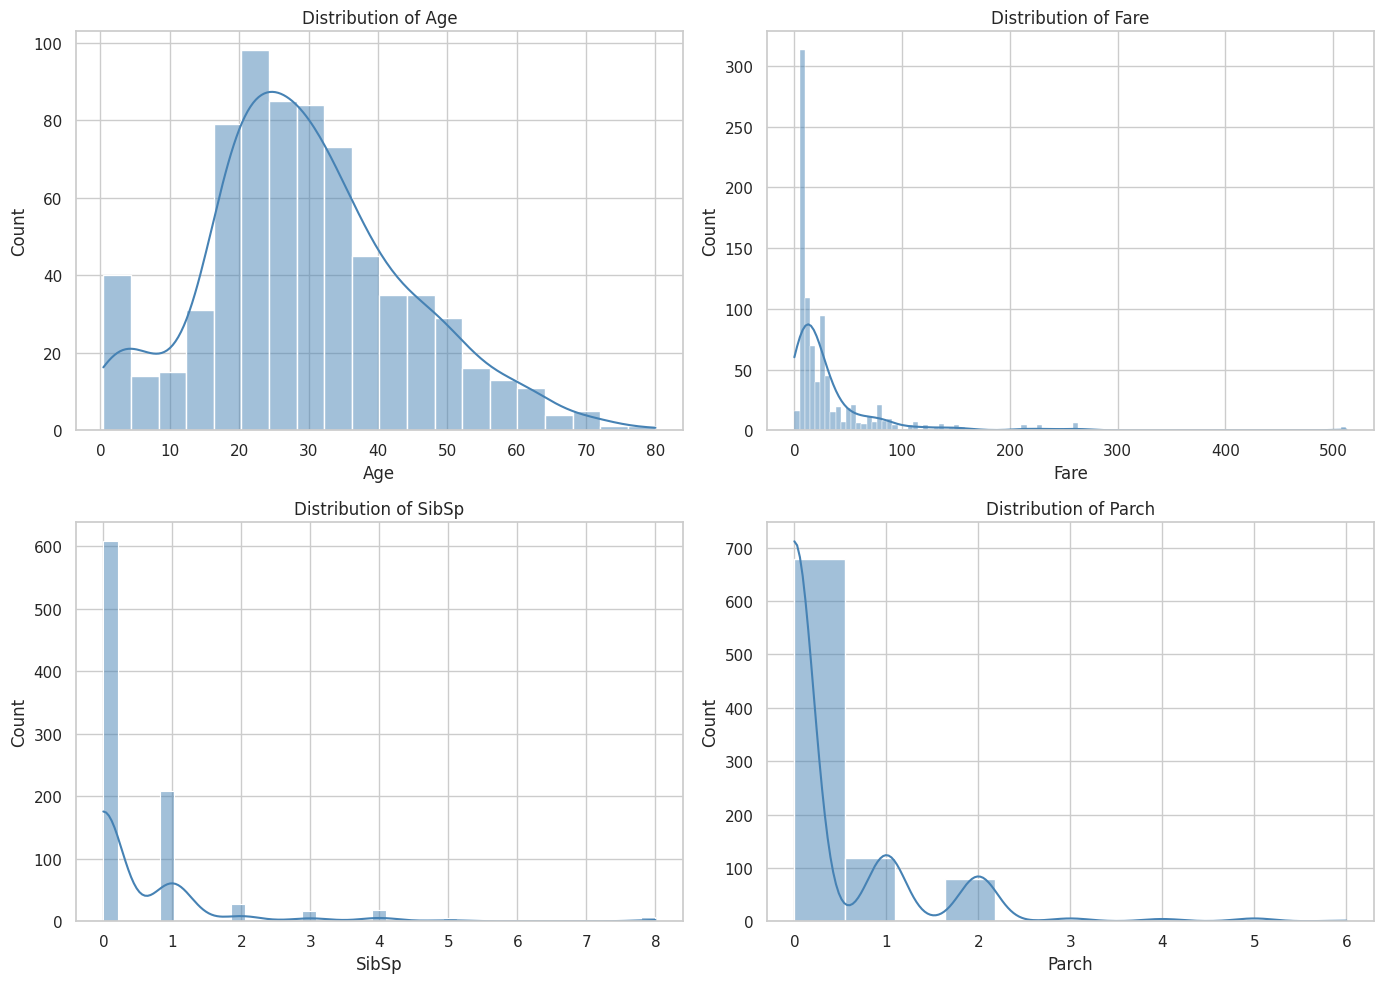

In [26]:
numeric_cols = ["Age", "Fare", "SibSp", "Parch"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for col, ax in zip(numeric_cols, axes.flatten()):
    sns.histplot(
        data=df, x=col, kde=True,
        ax=ax, color="steelblue"
    )
    ax.set_title(f"Distribution of {col}")

plt.tight_layout()
plt.show()

Interpretation to add in a text cell:
- Age: Observe the distribution of passenger ages and whether values are concentrated in particular age groups.
- Fare: Check whether most fares are low and whether a few passengers paid much higher fares.
- SibSp: Examine how many siblings or spouses passengers commonly travelled with.
- Parch: Examine the distribution of parents and children travelling with passengers.

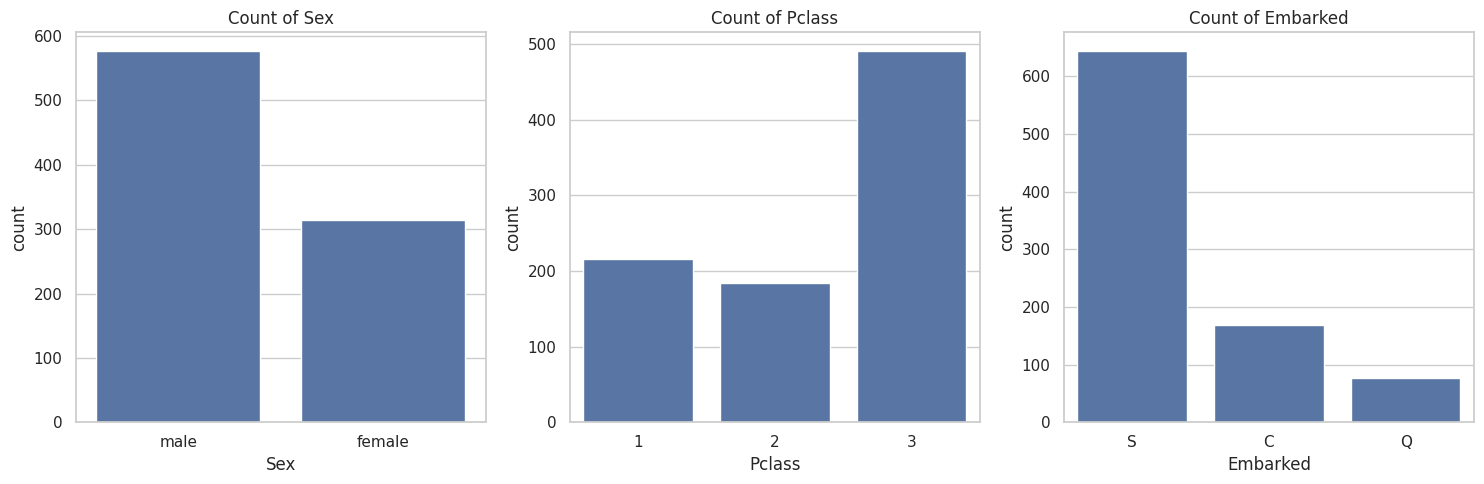

In [27]:
categorical_cols = ["Sex", "Pclass", "Embarked"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for col, ax in zip(categorical_cols, axes):
    sns.countplot(data=df, x=col, ax=ax)
    ax.set_title(f"Count of {col}")

plt.tight_layout()
plt.show()

Interpretation:
- Sex: Compare the numbers of male and female passengers.
- Pclass: Compare passenger counts in first, second, and third class.
- Embarked: Compare passenger counts by embarkation port.

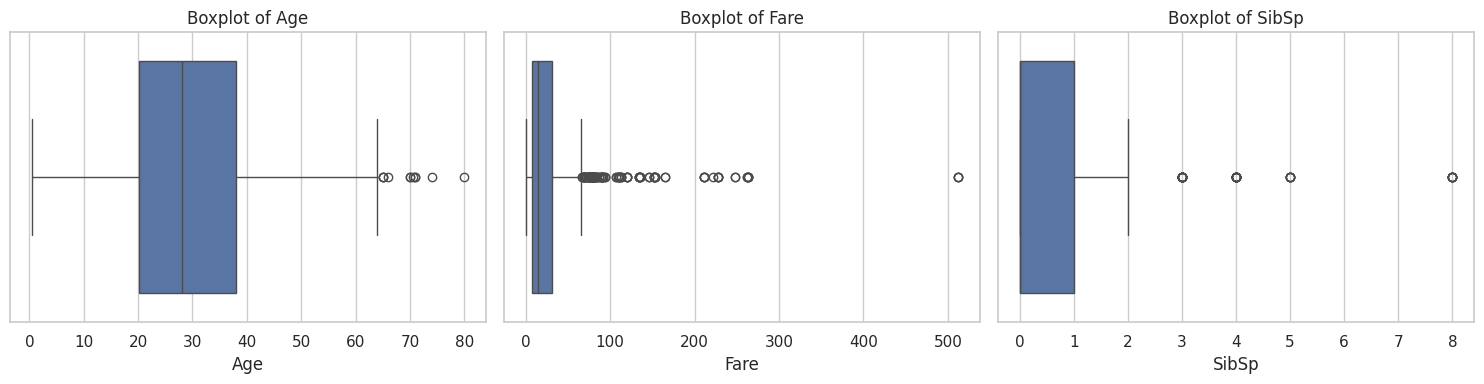

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for col, ax in zip(["Age", "Fare", "SibSp"], axes):
    sns.boxplot(data=df, x=col, ax=ax)
    ax.set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

Interpretation:

Boxplots show the median, quartiles, spread, and potential outliers. Points outside the whiskers are potential outliers, not automatically errors. For example, a high fare may reflect a genuine passenger ticket rather than incorrect data.

Survival counts:
Survived
0    549
1    342
Name: count, dtype: int64

Survival percentages:
Survived
0    61.62
1    38.38
Name: proportion, dtype: float64


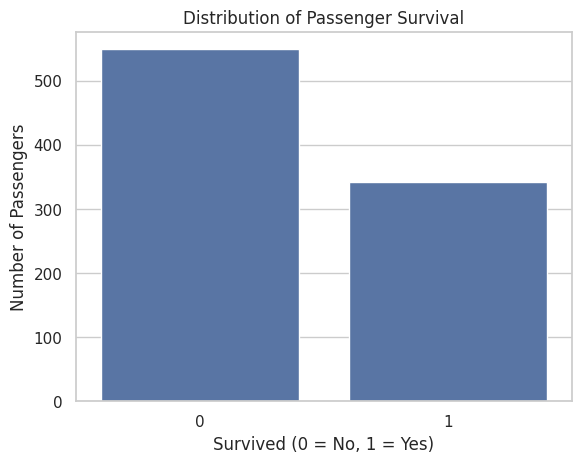

In [29]:
print("Survival counts:")
print(df["Survived"].value_counts().sort_index())

print("\nSurvival percentages:")
print(
    (df["Survived"].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

sns.countplot(data=df, x="Survived")
plt.title("Distribution of Passenger Survival")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.show()

The target variable has two classes: 0 for passengers who did not survive and 1 for passengers who survived. The bar chart shows the number of passengers in each class. If one class has a substantially larger count, the target is imbalanced. This matters because a future model could perform poorly on the smaller class if class imbalance is ignored.

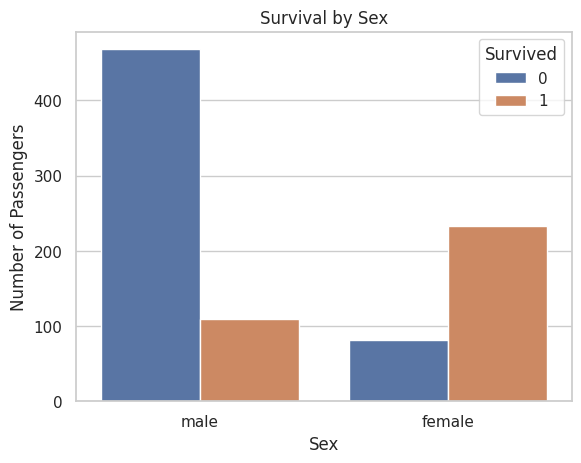

In [30]:
sns.countplot(data=df, x="Sex", hue="Survived")
plt.title("Survival by Sex")
plt.xlabel("Sex")
plt.ylabel("Number of Passengers")
plt.show()

Compare the survival and non-survival bars for males and females. Identify which group has a higher survival count and whether the pattern suggests an association between sex and survival.

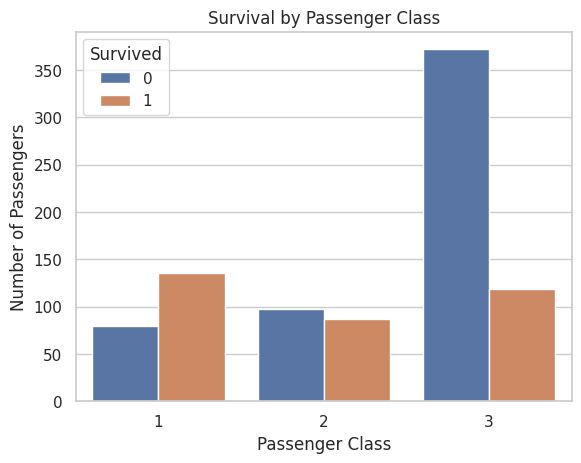

In [31]:
sns.countplot(data=df, x="Pclass", hue="Survived")
plt.title("Survival by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")
plt.show()

Compare the survival patterns in first, second, and third class. Remember that counts alone do not show survival rates when class sizes differ.

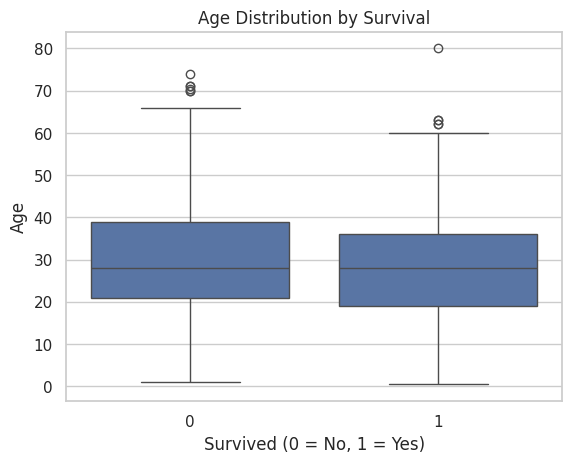

In [32]:
sns.boxplot(data=df, x="Survived", y="Age")
plt.title("Age Distribution by Survival")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Age")
plt.show()

Compare the median ages, spread, and potential outliers for survivors and non-survivors. Note whether the distributions appear different.

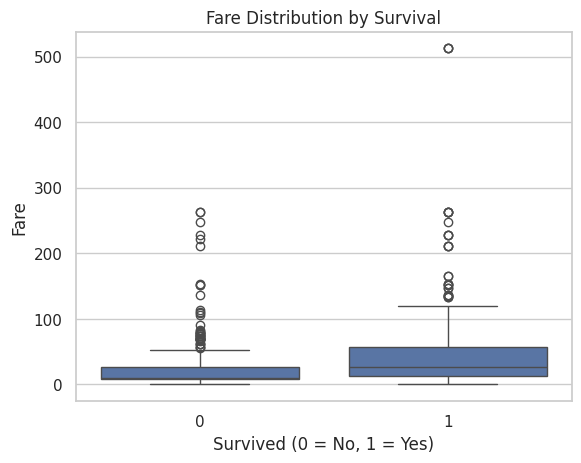

In [33]:
sns.boxplot(data=df, x="Survived", y="Fare")
plt.title("Fare Distribution by Survival")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Fare")
plt.show()

Compare the fare distributions of both groups. If the median fare is higher among survivors, report that association, but do not claim that fare alone caused survival.

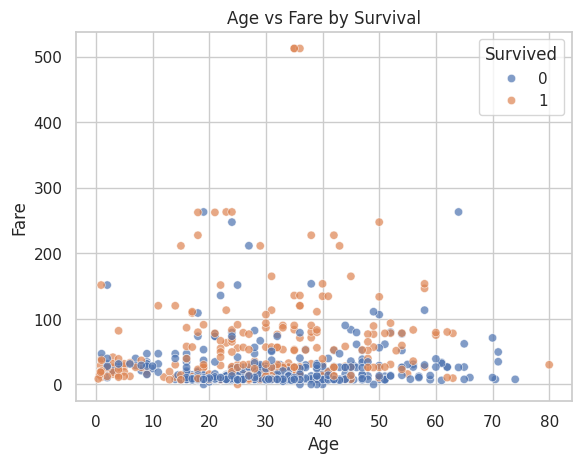

In [34]:
sns.scatterplot(
    data=df,
    x="Age",
    y="Fare",
    hue="Survived",
    alpha=0.7
)
plt.title("Age vs Fare by Survival")
plt.show()

Look for clusters, overlapping groups, and passengers with unusually high fares. Observe whether the survival classes appear differently distributed across age and fare.

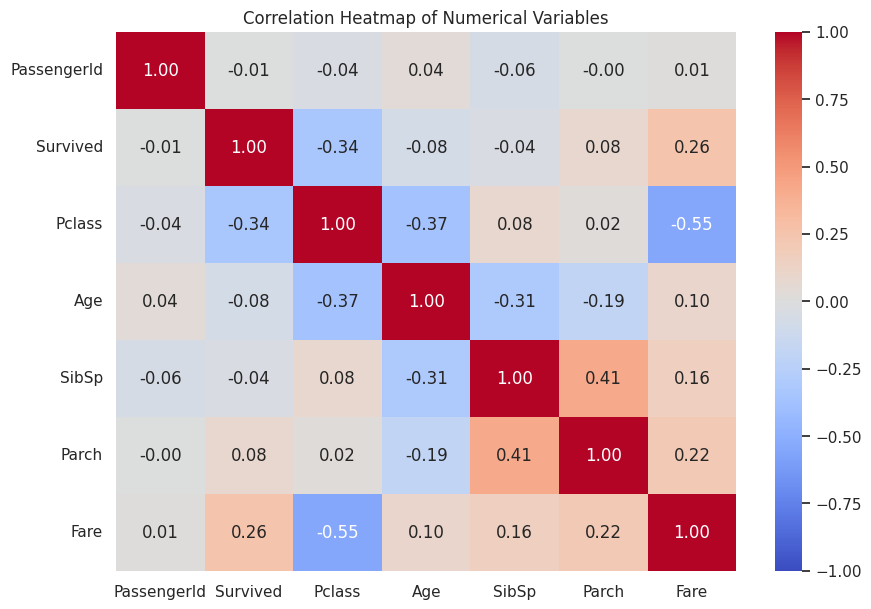

In [35]:
numeric_df = df.select_dtypes(include="number")

correlation = numeric_df.corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)
plt.title("Correlation Heatmap of Numerical Variables")
plt.show()

nterpretation: Correlation values range from -1 to +1. Values near +1 indicate strong positive linear relationships, values near -1 indicate strong negative linear relationships, and values near 0 indicate weak linear relationships. The heatmap should be examined to identify the strongest relationships, especially those involving Survived. Correlation does not establish causation.

Use these general guidelines when interpreting the heatmap:
Absolute correlation	General interpretation
0.00–0.19	Very weak
0.20–0.39	Weak
0.40–0.59	Moderate
0.60–0.79	Strong
0.80–1.00	Very strong
These are approximate guidelines, not universal rules. Also, a correlation close to zero does not rule out a nonlinear relationship.

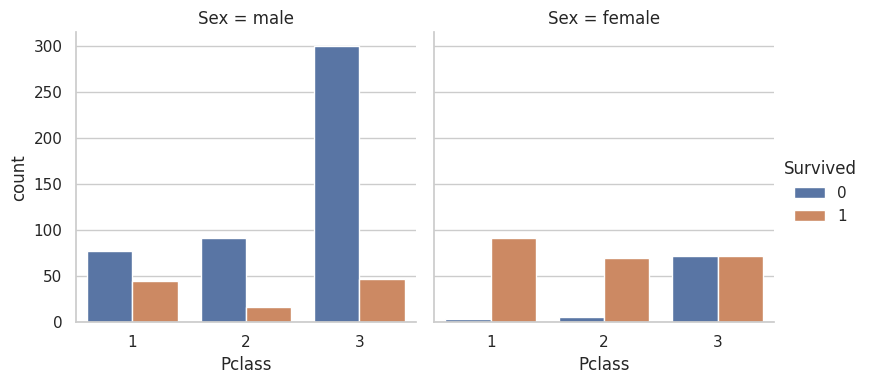

In [36]:
sns.catplot(
    data=df,
    x="Pclass",
    hue="Survived",
    col="Sex",
    kind="count",
    height=4,
    aspect=1
)
plt.show()

This visualization compares survival counts by passenger class separately for males and females. Look for combined patterns that are not as obvious when examining sex or class individually.

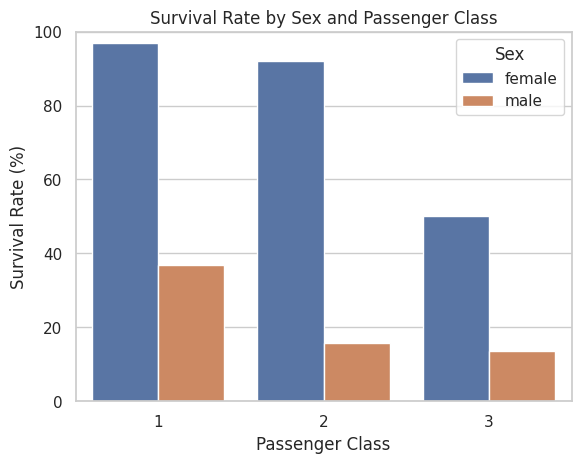

,Sex,Pclass,Survived,SurvivalRate
0,female,1,0.968085,96.808511
1,female,2,0.921053,92.105263
2,female,3,0.500000,50.000000
3,male,1,0.368852,36.885246
4,male,2,0.157407,15.740741
5,male,3,0.135447,13.544669


In [37]:
survival_rates = (
    df.groupby(["Sex", "Pclass"])["Survived"]
    .mean()
    .reset_index()
)

survival_rates["SurvivalRate"] = survival_rates["Survived"] * 100

sns.barplot(
    data=survival_rates,
    x="Pclass",
    y="SurvivalRate",
    hue="Sex"
)

plt.title("Survival Rate by Sex and Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate (%)")
plt.ylim(0, 100)
plt.show()

display(survival_rates)

Compare survival percentages across the six sex-and-class groups. Identify the groups with the highest and lowest survival rates based on the graph and table.

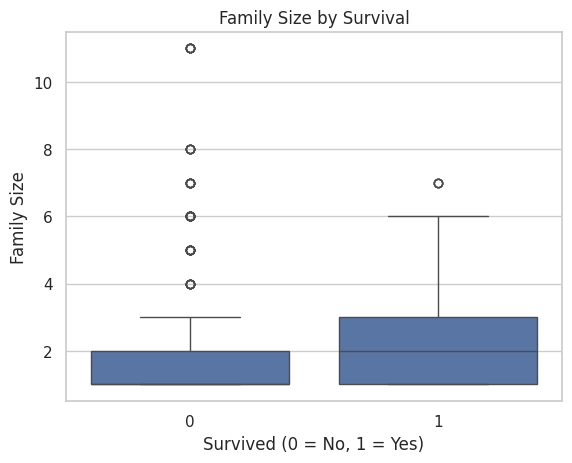

In [38]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

sns.boxplot(data=df, x="Survived", y="FamilySize")
plt.title("Family Size by Survival")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Family Size")
plt.show()

Compare family sizes among survivors and non-survivors. Look for differences between passengers travelling alone and those travelling with family. Treat these as exploratory observations, not proof of causation.

In [40]:
print("Highest fares:")
display(df.nlargest(5, "Fare")[["Name", "Pclass", "Fare", "Survived"]])

print("\nYoungest and oldest passengers:")
display(
    df.loc[df["Age"].idxmin(), ["Name", "Age", "Survived"]]
)
display(
    df.loc[df["Age"].idxmax(), ["Name", "Age", "Survived"]]
)

print("\nMissing values:")
print(df.isnull().sum())

print("\nFamily size counts:")
print(df["FamilySize"].value_counts().sort_index())

Highest fares:


,Name,Pclass,Fare,Survived
258,"Ward, Miss. Anna",1,512.3292,1
679,"Cardeza, Mr. Thomas Drake Martinez",1,512.3292,1
737,"Lesurer, Mr. Gustave J",1,512.3292,1
27,"Fortune, Mr. Charles Alexander",1,263.0000,0
88,"Fortune, Miss. Mabel Helen",1,263.0000,1



Youngest and oldest passengers:


,803
Name,"Thomas, Master. Assad Alexander"
Age,0.42
Survived,1


,630
Name,"Barkworth, Mr. Algernon Henry Wilson"
Age,80.0
Survived,1



Missing values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
FamilySize       0
IsAlone          0
dtype: int64

Family size counts:
FamilySize
1     537
2     161
3     102
4      29
5      15
6      22
7      12
8       6
11      7
Name: count, dtype: int64


Interpretation:
- Trends: Identify differences in survival across sex, passenger class, and age.
- Unusual observations: Investigate very high fares, unusually large families, and extreme ages.
- Missing data: The original dataset has many missing Cabin values and some missing Age values.
- Patterns: Check whether survival varies across combinations of sex, passenger class, and family size.

## Final Findings

1. **Dataset structure:** The Titanic training dataset contains 891 rows and 12 original columns. It includes numerical and categorical information suitable for exploratory analysis.

2. **Missing values:** The dataset contains missing values, particularly in the Cabin column, which must be considered when preparing data for future modeling.

3. **Age distribution:** The Age histogram and boxplot help reveal the distribution of passenger ages, their spread, and possible unusual observations.

4. **Fare distribution:** The Fare distribution should be examined for right skewness and unusually high ticket fares. A transformation may be considered later if appropriate for the chosen model.

5. **Survival distribution:** The target distribution shows the relative numbers of survivors and non-survivors. Its class balance should be considered when selecting model evaluation metrics.

6. **Sex and survival:** Comparing survival by sex helps determine whether survival outcomes differ between male and female passengers.

7. **Passenger class and survival:** Comparing passenger classes helps identify whether survival outcomes vary by class. Survival percentages are more informative than counts alone when group sizes differ.

8. **Combined patterns and modeling:** Multivariate analysis of sex, passenger class, age, fare, and family size helps identify potentially useful predictors. These observations can guide feature selection and later modeling, but relationships should be validated on separate data.

## Conclusion

Exploratory Data Analysis provided an overview of the Titanic dataset's structure, feature distributions, missing values, potential outliers, correlations, and survival patterns. Univariate, bivariate, and multivariate visualizations helped identify relationships that may be useful for future machine learning. The findings can guide feature selection, missing-value handling, and model evaluation. However, EDA reveals associations rather than proving causation, and predictive performance must be evaluated separately.